# Autonomous Trailer — Knowledge-Based Agent

**Group:** Kubai Dan (190226), Sydney Wairimu (192135), Jibril Jaafar (191831) 



## Step 1 — Identify the task
Our trailer carries cargo from **Nairobi to Kisumu**. It needs to select a low-distance route and respond sensibly when its surroundings or vehicle condition changes.

**Goal:** Choose the shortest feasible route in our directed road network while prioritising cargo and road-user safety.

**PEAS:** Performance: safety, legal compliance, cargo integrity, travel distance and fuel economy. Environment: highways, towns, traffic, weather and other road users. Actuators (conceptual): steering, throttle, brakes, lights and alerts. Sensors (conceptual): GPS, camera, radar, LiDAR, hitch-angle, tyre and load sensors.

The real driving environment is partially observable, stochastic, sequential, dynamic, continuous and multi-agent. Our simplified model uses discrete town-to-town transitions.

## Step 2 — Assemble relevant knowledge
We reuse the **12 towns and 14 directed edges** from Exercise 3. Edge weights represent the group's road-distance estimates in kilometres. The original alternative routes are 353 km (Kericho), 433 km (Kapsabet), 493 km (Kisii), and 657 km (Central Aberdare).

The knowledge base also stores simulated percepts: weather, traffic, obstacles, road closures, hitch angle, tyre condition, cargo security and fuel level.

**Provenance:** `design (1).md` and `UCS_Trailer(1).ipynb` (group Exercise 3). No external API or web scraping is required to reproduce this notebook; live updates would need verified sources and permissions.

In [2]:
import heapq
from dataclasses import dataclass, field
from typing import Dict, List, Set, Tuple, Optional

print("Knowledge-based trailer agent ready.")

Knowledge-based trailer agent ready.


In [1]:
graph = {
    'Nairobi': [('Naivasha', 88), ('Thika', 42)],
    'Thika': [('Nyeri', 85)],
    'Nyeri': [('Nanyuki', 105)],
    'Nanyuki': [('Naivasha', 160)],
    'Naivasha': [('Nakuru', 68)],
    'Nakuru': [('Kericho', 110), ('Eldoret', 140)],
    'Kericho': [('Kisumu', 87), ('Kisii', 112)],
    'Kisii': [('Kisumu', 115)],
    'Eldoret': [('Kapsabet', 64), ('Kitale', 120)],
    'Kapsabet': [('Kisumu', 73)],
    'Kitale': [],
    'Kisumu': []
}

start = 'Nairobi'
goal = 'Kisumu'

print('Start:', start)
print('Goal:', goal)
print('Number of directed road links:', sum(len(edges) for edges in graph.values()))
assert len(graph) == 12
assert sum(len(v) for v in graph.values()) == 14
print(f"Loaded {len(graph)} towns and {sum(map(len, graph.values()))} directed links.")

Start: Nairobi
Goal: Kisumu
Number of directed road links: 14
Loaded 12 towns and 14 directed links.


## Step 3 — Define the vocabulary
Our **constants** are town names and condition labels such as `heavy_rain`. Our **predicates/facts** include `ROAD_BLOCKED`, `OBSTACLE_AHEAD`, `JACKKNIFE_RISK`, `LOW_FUEL` and `CAUTION_REQUIRED`.

`Percepts` describes what the simulated sensors report. `KnowledgeBase` stores the current percepts, inferred facts and explanations. Every new observation replaces temporary conclusions so outdated hazards are not carried forward.

In [4]:
@dataclass
class Percepts:
    location: str = "Nairobi"
    weather: str = "clear"       # clear, light_rain, heavy_rain, fog
    traffic: str = "normal"      # normal, heavy
    obstacle: bool = False
    hitch_angle_deg: float = 0.0
    tyre_pressure_ok: bool = True
    cargo_secured: bool = True
    fuel_percent: float = 70.0
    blocked_edges: Set[Tuple[str, str]] = field(default_factory=set)

@dataclass
class KnowledgeBase:
    roads: dict
    percepts: Percepts = field(default_factory=Percepts)
    facts: Set[str] = field(default_factory=set)
    explanations: List[str] = field(default_factory=list)

    def observe(self, p: Percepts):
        if p.location not in self.roads:
            raise ValueError("Location is not in the road network")
        if p.weather not in {"clear", "light_rain", "heavy_rain", "fog"}:
            raise ValueError("Unknown weather condition")
        if p.traffic not in {"normal", "heavy"}:
            raise ValueError("Unknown traffic condition")
        if not 0 <= p.fuel_percent <= 100 or not 0 <= p.hitch_angle_deg <= 180:
            raise ValueError("Invalid simulated sensor reading")
        known_edges = {(u, v) for u, links in self.roads.items() for v, _ in links}
        if not p.blocked_edges <= known_edges:
            raise ValueError("Blocked edge not in the graph")
        self.percepts = p
        self.facts.clear()
        self.explanations.clear()

    def add(self, fact, reason):
        if fact not in self.facts:
            self.facts.add(fact)
            self.explanations.append(f"{fact} — {reason}")

## Step 4 — Encode general knowledge (IF–THEN rules)
The agent uses **forward chaining**: sensor observations create condition facts; those facts lead to an advisory decision. Rules are deliberately simple and explainable.

| Rule | IF | THEN |
|---|---|---|
| R1 | Heavy rain or fog | `CAUTION_REQUIRED` |
| R2 | Heavy traffic | `CAUTION_REQUIRED` |
| R3 | Obstacle detected | `STOP_AND_ALERT` |
| R4 | Hitch angle ≥ 40° | `STOP_AND_ALERT` |
| R5 | Tyre fault or unsecured cargo | `STOP_AND_ALERT` |
| R6 | Fuel below 15% | `REFUEL_ADVISORY` |
| R7 | Intended road link is closed | `REPLAN_REQUIRED` |

The 40° and 15% thresholds are **illustrative classroom assumptions**, not certified operating limits. A physical safety issue takes priority over route optimisation.

In [5]:
def infer(kb: KnowledgeBase):
    p = kb.percepts
    if p.weather in {"heavy_rain", "fog"}:
        kb.add("CAUTION_REQUIRED", "R1: severe weather")
    if p.traffic == "heavy":
        kb.add("CAUTION_REQUIRED", "R2: heavy traffic")
    if p.obstacle:
        kb.add("STOP_AND_ALERT", "R3: obstacle detected")
    if p.hitch_angle_deg >= 40:
        kb.add("STOP_AND_ALERT", "R4: excessive simulated articulation")
    if not p.tyre_pressure_ok or not p.cargo_secured:
        kb.add("STOP_AND_ALERT", "R5: tyre or cargo safety problem")
    if p.fuel_percent < 15:
        kb.add("REFUEL_ADVISORY", "R6: low fuel")
    if p.blocked_edges:
        kb.add("REPLAN_REQUIRED", "R7: road closure reported")
    return kb.facts

def choose_action(facts):
    for action in ("STOP_AND_ALERT", "REPLAN_REQUIRED", "REFUEL_ADVISORY", "CAUTION_REQUIRED"):
        if action in facts:
            return action
    return "PROCEED_NORMALLY"

## Step 5 — Add facts to the knowledge base
Road connections are persistent facts from Exercise 3. Weather, fuel and obstacles are changing facts. Below, we inspect the knowledge base without changing the original route distances.

In [6]:
kb = KnowledgeBase(graph)
kb.observe(Percepts(location="Nairobi", weather="heavy_rain", fuel_percent=55))
infer(kb)
print("Current location:", kb.percepts.location)
print("Known road links:", sum(len(v) for v in kb.roads.values()))
print("Derived facts:", sorted(kb.facts))
print("Reasoning:", *kb.explanations, sep="\n - ")

Current location: Nairobi
Known road links: 14
Derived facts: ['CAUTION_REQUIRED']
Reasoning:
 - CAUTION_REQUIRED — R1: severe weather


## Step 6 — Encode a specific problem instance
We start in Nairobi, aim for Kisumu, and assume no reported road closure. This represents one **simulated** trip, not a live GPS feed.

In [7]:
start, goal = "Nairobi", "Kisumu"
trip = Percepts(location=start, weather="clear", traffic="normal", fuel_percent=70)
kb.observe(trip)
print("Start:", start, "| Goal:", goal, "| Conditions:", trip.weather)

Start: Nairobi | Goal: Kisumu | Conditions: clear


## Step 7 — Pose queries and get answers (Uniform Cost Search)
The agent asks: **Which reachable route has the lowest accumulated distance?** UCS expands the cheapest frontier entry first. Closed links are excluded; the algorithm does not invent new roads.

In [8]:
def uniform_cost_search(roads, start, goal, blocked_edges=None):
    if start not in roads or goal not in roads:
        raise ValueError("Unknown start or destination")
    blocked_edges = blocked_edges or set()
    frontier = [(0.0, start, [start])]
    best = {start: 0.0}
    expansions = []
    while frontier:
        cost, town, path = heapq.heappop(frontier)
        if cost > best.get(town, float("inf")):
            continue
        expansions.append((town, cost))
        if town == goal:
            return {"path": path, "cost": cost, "expansions": expansions}
        for neighbor, km in roads[town]:
            if km < 0:
                raise ValueError("Negative distance")
            if (town, neighbor) in blocked_edges:
                continue
            candidate = cost + km
            if candidate < best.get(neighbor, float("inf")):
                best[neighbor] = candidate
                heapq.heappush(frontier, (candidate, neighbor, path + [neighbor]))
    return {"path": None, "cost": None, "expansions": expansions}

answer = uniform_cost_search(graph, start, goal)
print("Shortest route:", " → ".join(answer["path"]))
print("Total:", answer["cost"], "km")
print("UCS expansion order:", " → ".join(n for n, _ in answer["expansions"]))
assert answer["cost"] == 353

Shortest route: Nairobi → Naivasha → Nakuru → Kericho → Kisumu
Total: 353.0 km
UCS expansion order: Nairobi → Thika → Naivasha → Nyeri → Nakuru → Nanyuki → Kericho → Eldoret → Kisumu


## Step 8 — Query the agent with different situations
This combines **observation → KB update → inference → route planning → explanation**. It produces a recommendation rather than physical vehicle commands. If a closed link makes the destination unreachable, the agent reports that honestly.

In [10]:
def trailer_agent(percepts: Percepts, destination="Kisumu"):
    knowledge = KnowledgeBase(graph)
    knowledge.observe(percepts)
    facts = infer(knowledge)
    route = uniform_cost_search(graph, percepts.location, destination, percepts.blocked_edges)
    action = choose_action(facts)
    if percepts.location == destination:
        action = "ARRIVED" if action != "STOP_AND_ALERT" else action
    elif route["path"] is None and action != "STOP_AND_ALERT":
        action = "NO_SAFE_ROUTE"
    elif action == "REPLAN_REQUIRED":
        action = "ALTERNATIVE_ROUTE_FOUND" if route["path"] else "NO_SAFE_ROUTE"
    messages = {
        "STOP_AND_ALERT": "Safety problem: stop safely and alert the human operator.",
        "NO_SAFE_ROUTE": "No route available in our directed graph. Wait for updated information.",
        "ALTERNATIVE_ROUTE_FOUND": "An alternative route exists in our model; verify before use.",
        "REFUEL_ADVISORY": "Plan a verified fuel stop.",
        "CAUTION_REQUIRED": "Conditions require caution and human oversight.",
        "PROCEED_NORMALLY": "No modelled hazard detected; the planned route is available.",
        "ARRIVED": "Destination reached in the simulated model."
    }
    return {"action": action, "route": route["path"], "distance_km": route["cost"],
            "facts": sorted(facts), "why": knowledge.explanations, "advice": messages[action]}

def display_result(name, p):
    result = trailer_agent(p)
    print(f"\n{name}\nDecision: {result['action']}")
    print("Route:", " → ".join(result["route"]) if result["route"] else "Unavailable")
    print("Distance:", result["distance_km"], "km")
    print("Advice:", result["advice"])
    for line in result["why"]:
        print(" •", line)
    return result

normal = display_result("Normal trip", Percepts())
rain = display_result("Heavy rain near Nakuru", Percepts(location="Nakuru", weather="heavy_rain"))
obstacle = display_result("Obstacle near Kericho", Percepts(location="Kericho", obstacle=True))
closure = display_result("Kericho → Kisumu closed", Percepts(
    location="Kericho", blocked_edges={("Kericho", "Kisumu")}))


Normal trip
Decision: PROCEED_NORMALLY
Route: Nairobi → Naivasha → Nakuru → Kericho → Kisumu
Distance: 353.0 km
Advice: No modelled hazard detected; the planned route is available.

Heavy rain near Nakuru
Decision: CAUTION_REQUIRED
Route: Nakuru → Kericho → Kisumu
Distance: 197.0 km
Advice: Conditions require caution and human oversight.
 • CAUTION_REQUIRED — R1: severe weather

Obstacle near Kericho
Decision: STOP_AND_ALERT
Route: Kericho → Kisumu
Distance: 87.0 km
Advice: Safety problem: stop safely and alert the human operator.
 • STOP_AND_ALERT — R3: obstacle detected

Kericho → Kisumu closed
Decision: ALTERNATIVE_ROUTE_FOUND
Route: Kericho → Kisii → Kisumu
Distance: 227.0 km
Advice: An alternative route exists in our model; verify before use.
 • REPLAN_REQUIRED — R7: road closure reported


### Exercise 3 alternative routes and search-tree interpretation
The original directed graph branches at Nairobi, Nakuru, Kericho and Eldoret. That branching allows the agent to compare routes and recover from some closures. The following candidate costs are reproduced from the group work.

In [9]:
candidate_routes = {
    "A — Kericho": ["Nairobi","Naivasha","Nakuru","Kericho","Kisumu"],
    "B — Kapsabet": ["Nairobi","Naivasha","Nakuru","Eldoret","Kapsabet","Kisumu"],
    "C — Kisii": ["Nairobi","Naivasha","Nakuru","Kericho","Kisii","Kisumu"],
    "D — Aberdare": ["Nairobi","Thika","Nyeri","Nanyuki","Naivasha","Nakuru","Kericho","Kisumu"]
}
def path_distance(path):
    return sum(next(km for dest, km in graph[a] if dest == b)
               for a, b in zip(path, path[1:]))
for label, path in candidate_routes.items():
    print(f"{label:17} {path_distance(path):>4} km")
assert [path_distance(p) for p in candidate_routes.values()] == [353,433,493,657]

A — Kericho        353 km
B — Kapsabet       433 km
C — Kisii          493 km
D — Aberdare       657 km


### Visualise the directed highway graph
This plot uses a **schematic layout**, not GPS coordinates. Arrows show permitted travel direction and labels show Exercise 3 distances. The green route (when plotting colours are available) is the 353 km UCS path.

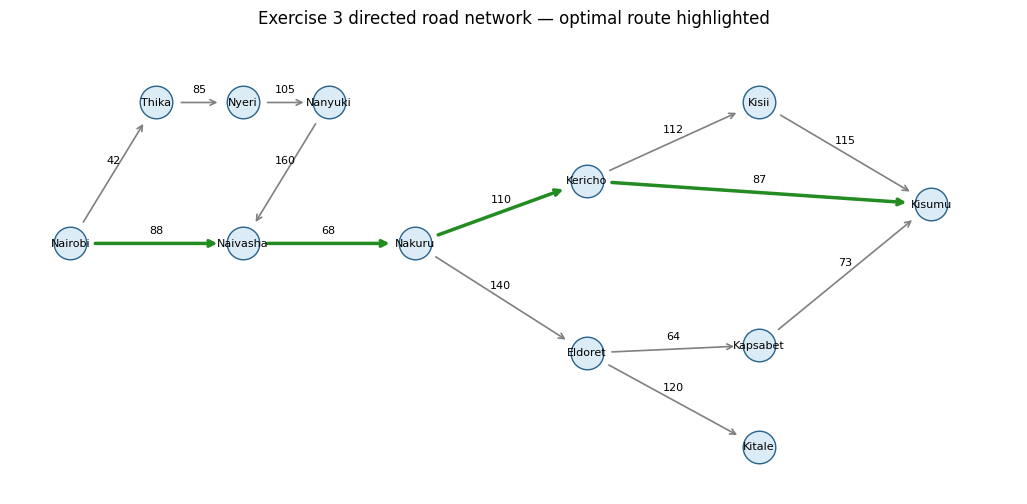

In [10]:
import matplotlib.pyplot as plt
positions = {
    "Nairobi": (0,2), "Thika": (1,3.8), "Nyeri": (2,3.8),
    "Nanyuki": (3,3.8), "Naivasha": (2,2), "Nakuru": (4,2),
    "Kericho": (6,2.8), "Kisii": (8,3.8), "Kisumu": (10,2.5),
    "Eldoret": (6,0.6), "Kapsabet": (8,0.7), "Kitale": (8,-0.6)
}
fig, ax = plt.subplots(figsize=(13,6))
optimal_edges = set(zip(answer["path"], answer["path"][1:]))
for u, links in graph.items():
    for v, km in links:
        x1,y1=positions[u]; x2,y2=positions[v]
        highlight = (u,v) in optimal_edges
        ax.annotate("", xy=(x2,y2), xytext=(x1,y1),
                    arrowprops=dict(arrowstyle="->", lw=2.5 if highlight else 1.2,
                                    color="forestgreen" if highlight else "gray",
                                    shrinkA=18, shrinkB=18))
        ax.text((x1+x2)/2, (y1+y2)/2+0.12, str(km), fontsize=8, ha="center")
for town,(x,y) in positions.items():
    ax.scatter(x,y,s=550,color="#dcecf6",edgecolor="#28628c",zorder=3)
    ax.text(x,y,town,ha="center",va="center",fontsize=8,zorder=4)
ax.set_xlim(-0.7,11);ax.set_ylim(-1.2,4.7)
ax.axis("off");ax.set_title("Exercise 3 directed road network — optimal route highlighted")
plt.show()

## Step 9 — Debug and test the knowledge base
These checks verify the shortest route, alternative-route selection, obstacle priority, low fuel, and invalid input. They also show that an unreachable destination is reported instead of guessed.

In [11]:
assert trailer_agent(Percepts())["distance_km"] == 353
assert trailer_agent(Percepts(obstacle=True, weather="fog"))["action"] == "STOP_AND_ALERT"
assert trailer_agent(Percepts(fuel_percent=8))["action"] == "REFUEL_ADVISORY"
assert trailer_agent(Percepts(weather="fog"))["action"] == "CAUTION_REQUIRED"
assert trailer_agent(Percepts(blocked_edges={("Kericho","Kisumu")}))["distance_km"] == 433
assert trailer_agent(Percepts(blocked_edges={
    ("Kericho","Kisumu"), ("Kericho","Kisii"), ("Kapsabet","Kisumu")
}))["action"] == "NO_SAFE_ROUTE"
try:
    trailer_agent(Percepts(location="Unknown"))
except ValueError:
    print("Invalid location correctly rejected.")
else:
    raise AssertionError("Unknown location should be rejected")
print("All knowledge-base tests passed.")

Invalid location correctly rejected.
All knowledge-base tests passed.


## Step 10 — Reflection and possible improvements
We developed a knowledge-based trailer agent by combining the **directed graph and Uniform Cost Search from Exercise 3** with explicit sensor facts and IF–THEN safety rules. It can explain decisions, select the lowest-distance route in our model, and find a different route when a link is blocked.

**Challenges:** Real road conditions are unpredictable, road distances can change with mapping choices, and a simple town-level graph cannot model braking, lane changes, or trailer dynamics. Simulated percepts cannot establish that a road is safe.

**Future improvements:** Add verified map and traffic APIs (with permission and attribution), timestamped weather information, real road restrictions for heavy vehicles, verified fuel stations, more detailed junction data, and uncertainty-aware reasoning. Any real vehicle control would require extensive testing and certified safety systems.

**References / source notes:** Group Exercise 3 `design (1).md` and `UCS_Trailer(1).ipynb`; Python standard library (`heapq`, `dataclasses`). Distances are reused academic estimates, not live measurements.